# Analisis Exploratorio de Mapas.

La información electoral es información georeferenciada. Entonces vamos a descargar los mapas referentes 

In [62]:
# from partciud.prepare_maps import download_maps
from partciud.config import DATA_FOLDER
from partciud.repair_shp import repair
import os
import matplotlib.pyplot as plt
import geopandas as gpd

# download_maps()

In [63]:
INE_MAPS_FOLDER = DATA_FOLDER / "interim" / "ine_maps"
for folder in os.listdir(INE_MAPS_FOLDER):
    print(folder)
    repair(INE_MAPS_FOLDER / folder, check_only=True)

2019
Todos los shapefiles están correctos.
2020
Todos los shapefiles están correctos.
2021
Todos los shapefiles están correctos.
2022
Todos los shapefiles están correctos.
2023
Todos los shapefiles están correctos.
2024
Todos los shapefiles están correctos.
2025
Todos los shapefiles están correctos.


## Caso ejemplo.


In [65]:
YEAR = 2019
elec_folder = DATA_FOLDER / "interim" / "ine_maps" / str(YEAR)
elec_maps = [m for m in os.listdir(elec_folder) if m.endswith(".shp")]
elec_maps

['ENTIDAD.shp',
 'MUNICIPIO.shp',
 'DISTRITO_FEDERAL.shp',
 'DISTRITO_LOCAL.shp',
 'SECCION.shp',
 'LOCALIDAD.shp',
 'MANZANAS.shp',
 'LOCALIDADES_URBANAS.shp',
 'LOCALIDADES_RURALES.shp']

Con los mapas. Haremos la selección de los mapas necesarios. 

### Municipios

Comenzaremos con la división municipal. La división minima territorial requerida. Nomas notemos que este analisis se centrará en Sonora.

MUNICIPIO.shp


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

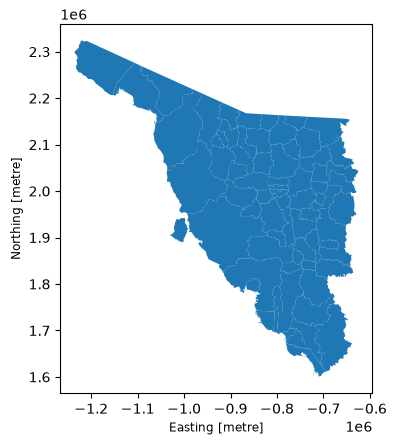

In [66]:
sonora_key = 26  # Nos centraremos en Sonora
print(elec_maps[1])
mun_map = gpd.read_file(elec_folder / elec_maps[1])
sonora_munmap = mun_map[mun_map['ENTIDAD'] == sonora_key].reset_index(drop=True)
sonora_munmap.plot()

In [67]:
# Función auxiliar para seleccionar Sonora
def ent_mask(df, key=sonora_key):
    mask_df = df[df['ENTIDAD']==key]
    return mask_df

### Distrito Locales.

Como nos centraremos en Sonora. Usaremos los Distritos definidos por el IEE Sonora.

DISTRITO_LOCAL.shp


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

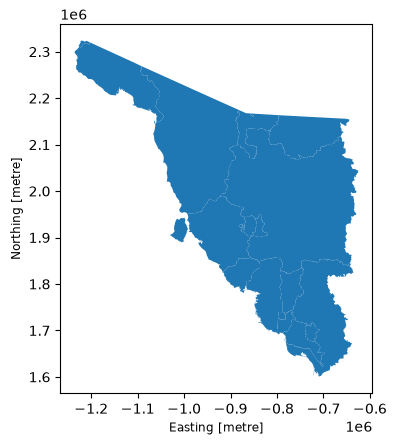

In [68]:
print(elec_maps[3])
distrito_local_map = gpd.read_file(elec_folder / elec_maps[3])
sonora_dislmap = ent_mask(distrito_local_map).reset_index(drop=True)
sonora_dislmap.plot()

### Secciones

Dentro de la división minima de las elecciones son las secciones. 

SECCION.shp


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

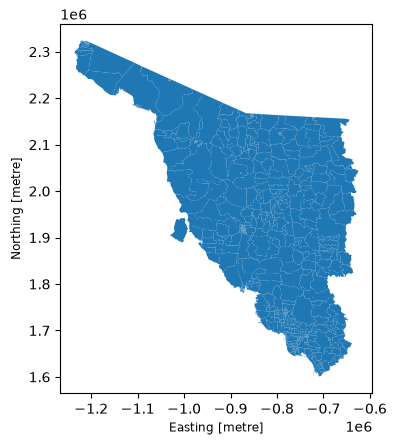

In [69]:
print(elec_maps[4])
seccion_map = gpd.read_file(elec_folder / elec_maps[4])
sonora_secmap = ent_mask(seccion_map).reset_index(drop=True)
sonora_secmap.plot()

Viendo los mapas anteriores. Notamos que no requerimos el mapa de los distritos porque los podemos obtener del mapa de la sección.

In [70]:
sonora_secmap.columns

Index(['ID', 'ENTIDAD', 'DISTRITO_F', 'DISTRITO_L', 'MUNICIPIO', 'SECCION',
       'TIPO', 'Geometry1_', 'PADRON', 'LISTA', 'geometry'],
      dtype='str')

Entonces haremos una selección de variables relevantes, como el nombre del municipio.

In [71]:
sonora_muns = sonora_munmap[['MUNICIPIO','NOMBRE']].set_index('MUNICIPIO')
geodata = sonora_secmap.drop(columns=["ID", "DISTRITO_F", "Geometry1_"])
geodata['MUNICIPIONOMBRE'] = geodata['MUNICIPIO'].apply(lambda x: sonora_muns.loc[x, "NOMBRE"])
geodata.head()


,ENTIDAD,DISTRITO_L,MUNICIPIO,SECCION,TIPO,PADRON,LISTA,geometry,MUNICIPIONOMBRE
0,26,6,49,500,2,802,795,"POLYGON ((-873889.766 1917932.556, -873947.117...",HERMOSILLO
1,26,9,49,469,2,400,394,"POLYGON ((-871280.791 1918597.502, -871289.972...",HERMOSILLO
2,26,9,49,470,2,517,507,"POLYGON ((-871811.278 1919141.06, -871620.182 ...",HERMOSILLO
3,26,10,49,358,2,1502,1475,"POLYGON ((-872143.06 1923334.493, -871953.918 ...",HERMOSILLO
4,26,10,49,361,2,915,905,"POLYGON ((-872093.233 1922707.877, -872097.475...",HERMOSILLO


Finalmente, haremos una generalización de los mapas necesarios.

In [85]:
def create_ieegeodata(municipio: GeoDataFrame, seccion: GeoDataFrame, ent_id=None):
    """
        Crearemos el mapa con la información georeferenciada de las elecciones.
        municipio: Mapa de los municipios correspondientes.
        seccion: Mapa de las Secciones Electorales de la zona correspondiente.
        entidad: Clave del Estado de interes. Valor por defecto, México.
    """
    municipio.columns = [mun.lower() for mun in municipio.columns]
    seccion.columns = [sec.lower() for sec in seccion.columns]
    valid_ent= municipio['entidad'].unique().tolist()
    if ent_id != None:
        assert ent_id in valid_ent, "Selecciona una clave de estado válida"
        municipio = municipio[municipio['entidad'] == ent_id]
        seccion = seccion[seccion['entidad'] == ent_id]
    catalog = municipio[['entidad','municipio','nombre']]
    seccion = seccion.merge(catalog,
                            on=['entidad', 'municipio'],
                            how="left")
    seccion = seccion.reindex(columns=['entidad', 'municipio', 'nombre', 'distrito_l',
     'seccion', "tipo", "padron", "lista", "geometry"])
    return seccion
create_ieegeodata(mun_map, seccion_map)

,entidad,municipio,nombre,distrito_l,seccion,tipo,padron,lista,geometry
0,2,2,MEXICALI,3,264,2,693,692,"POLYGON ((-1271718.392 2347098.134, -1271693.8..."
1,2,1,ENSENADA,16,73,2,698,696,"POLYGON ((-1385364.954 2270099.657, -1385360.4..."
2,2,2,MEXICALI,3,266,2,722,721,"POLYGON ((-1270786.061 2347019.585, -1270786.2..."
3,2,1,ENSENADA,16,77,2,1055,1047,"POLYGON ((-1386581.411 2269748.896, -1386564.5..."
4,2,1,ENSENADA,16,78,2,834,830,"POLYGON ((-1385939.246 2269774.543, -1385935.6..."
...,...,...,...,...,...,...,...,...,...
68431,16,17,CONTEPEC,3,286,3,1952,1898,"POLYGON ((195024.118 888215.278, 194958.302 88..."
68432,30,68,ESPINAL,6,1523,4,1693,1685,"MULTIPOLYGON (((468398.043 920979.769, 468481...."
68433,21,192,TUZAMAPAN DE GALEANA,5,2327,4,1572,1535,"POLYGON ((469811.901 914555.667, 469816.703 91..."
68434,28,21,EL MANTE,17,491,3,720,717,"POLYGON ((353716.38 1170405.422, 353540.209 11..."


Finalmente, aplicaremos esto para cada año disponible.

## Preparacion de Mapas

In [96]:
YEAR = 2019

elec_folder = DATA_FOLDER / "interim" / "ine_maps" / f"{YEAR}"
sec = elec_folder / "SECCION.shp"
mun = elec_folder / "MUNICIPIO.shp"

secmap = gpd.read_file(sec)
munmap = gpd.read_file(mun)
print(YEAR, secmap.shape, munmap.shape)
data = create_ieegeodata(munmap, secmap, ent_id=26)
os.makedirs(DATA_FOLDER / "processed" / f"{YEAR}", exist_ok=True)
data.to_file(DATA_FOLDER / "processed" / f"{YEAR}" / f"map{YEAR}.shp")


2019 (68436, 11) (2458, 6)


In [97]:
YEAR = 2020

elec_folder = DATA_FOLDER / "interim" / "ine_maps" / f"{YEAR}"
sec = elec_folder / "SECCION.shp"
mun = elec_folder / "MUNICIPIO.shp"

secmap = gpd.read_file(sec)
munmap = gpd.read_file(mun)
print(YEAR, secmap.shape, munmap.shape)
data = create_ieegeodata(munmap, secmap, ent_id=26)
os.makedirs(DATA_FOLDER / "processed" / f"{YEAR}", exist_ok=True)
data.to_file(DATA_FOLDER / "processed" / f"{YEAR}" / f"map{YEAR}.shp")

2020 (68436, 12) (2458, 9)


In [98]:
YEAR = 2021

elec_folder = DATA_FOLDER / "interim" / "ine_maps" / f"{YEAR}"
sec = elec_folder / "SECCION.shp"
mun = elec_folder / "MUNICIPIO.shp"

secmap = gpd.read_file(sec)
munmap = gpd.read_file(mun)
print(YEAR, secmap.shape, munmap.shape)
data = create_ieegeodata(munmap, secmap, ent_id=26)
os.makedirs(DATA_FOLDER / "processed" / f"{YEAR}", exist_ok=True)
data.to_file(DATA_FOLDER / "processed" / f"{YEAR}" / f"map{YEAR}.shp")

2021 (68806, 12) (2468, 9)


In [99]:
YEAR = 2022

elec_folder = DATA_FOLDER / "interim" / "ine_maps" / f"{YEAR}"
sec = elec_folder / "SECCION" /"SECCION.shp"
mun = elec_folder / "MUNICIPIO" /"MUNICIPIO.shp"

secmap = gpd.read_file(sec)
munmap = gpd.read_file(mun)
print(YEAR, secmap.shape, munmap.shape)
data = create_ieegeodata(munmap, secmap, ent_id=26)
os.makedirs(DATA_FOLDER / "processed" / f"{YEAR}", exist_ok=True)
data.to_file(DATA_FOLDER / "processed" / f"{YEAR}" / f"map{YEAR}.shp")

2022 (69197, 11) (2469, 8)


In [100]:
YEAR = 2023

elec_folder = DATA_FOLDER / "interim" / "ine_maps" / f"{YEAR}"
sec = elec_folder / "SECCION.shp"
mun = elec_folder / "MUNICIPIO.shp"

secmap = gpd.read_file(sec)
munmap = gpd.read_file(mun)
print(YEAR, secmap.shape, munmap.shape)
data = create_ieegeodata(munmap, secmap, ent_id=26)
os.makedirs(DATA_FOLDER / "processed" / f"{YEAR}", exist_ok=True)
data.to_file(DATA_FOLDER / "processed" / f"{YEAR}" / f"map{YEAR}.shp")

2023 (66741, 12) (2469, 8)


In [101]:
YEAR = 2024

elec_folder = DATA_FOLDER / "interim" / "ine_maps" / f"{YEAR}"
sec = elec_folder / "SECCION" / "SECCION.shp"
mun = elec_folder / "MUNICIPIO" / "MUNICIPIO.shp"

secmap = gpd.read_file(sec)
munmap = gpd.read_file(mun)
print(YEAR, secmap.shape, munmap.shape)
data = create_ieegeodata(munmap, secmap, ent_id=26)
os.makedirs(DATA_FOLDER / "processed" / f"{YEAR}", exist_ok=True)
data.to_file(DATA_FOLDER / "processed" / f"{YEAR}" / f"map{YEAR}.shp")

2024 (70753, 11) (2477, 8)


In [103]:
YEAR = 2025

elec_folder = DATA_FOLDER / "interim" / "ine_maps" / f"{YEAR}"
sec = elec_folder / "SECCIONES_26"/ "SECCION_26.shp"
mun = elec_folder / "MUNICIPIO_26" / "MUNICIPIO_26.shp"

secmap = gpd.read_file(sec)
munmap = gpd.read_file(mun)
print(YEAR, secmap.shape, munmap.shape)
data = create_ieegeodata(munmap, secmap, ent_id=26)
os.makedirs(DATA_FOLDER / "processed" / f"{YEAR}", exist_ok=True)
data.to_file(DATA_FOLDER / "processed" / f"{YEAR}" / f"map{YEAR}.shp")

2025 (73268, 11) (2477, 8)
